<a href="https://colab.research.google.com/github/sigvehaug/MLwPython/blob/master/1_ML_Concepts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predict passengers using Random Forest and Neuronal Networks

Basic machine learning using regression methods with Python.

Simon Schüpbach, 2026. https://github.com/SimonSchuepbach/CAS-ADS-2026-Projects.git



### Main Goals in that Notebook

- Load passenger data of two touristic lines from PostAuto
- Transform the data set to be processed using the methods we learned in module 3
- Do some feature engineering for the preparation of the data set as model input.
- Apply a random forest regression and a neuronal network to the imported data set.

# Table of Content


1. Loading passenger data
2. Acquire daily weather and holiday data
3. Create features data frame 
4. Applying the models
    
    4.1 Random Forest

    4.2 Neuronal Network
5. Conclusion


## Load the libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from copy import deepcopy

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, log_loss

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from matplotlib import pyplot as plt # samesame import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

## 1. Load and inspect the passenger data (exploratory data analysis)
The data set is providing the number of passengers by trip and line of two touristic lines from 01.01.2024 to 31.08.2026.

In [2]:
data_path = Path("..") / ".." / "data" / "afz_trip_and_day_resolution_syslines_2601_651_202401-202608.csv"

line_data_by_trip = pd.read_csv(data_path,sep=',')

line_data_by_trip.info()


<class 'pandas.DataFrame'>
RangeIndex: 212001 entries, 0 to 212000
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   operatingday      212001 non-null  str    
 1   weekday           212001 non-null  str    
 2   vehicleid         212001 non-null  int64  
 3   tripinstanceid    212001 non-null  str    
 4   systemlinenumber  212001 non-null  int64  
 5   tripnumber        212001 non-null  int64  
 6   directionid       212001 non-null  int64  
 7   departure         212001 non-null  str    
 8   boarding_by_trip  211279 non-null  float64
 9   year_month        212001 non-null  str    
 10  month             212001 non-null  int64  
 11  quart             212001 non-null  str    
 12  weekdaytype       212001 non-null  str    
 13  year              212001 non-null  int64  
dtypes: float64(1), int64(6), str(7)
memory usage: 22.6 MB


The passengers are now summarized by day, weekday, weekdaytype, line number, direction and time of day (morning vs evening).

In [4]:
line_data_by_trip["departure"] = (
    pd.to_datetime(line_data_by_trip["departure"], utc=True)
    .dt.tz_convert("Europe/Zurich")
)
line_data_by_trip["departure_h"] = line_data_by_trip["departure"].dt.hour
line_data_by_trip["time_of_day"] = np.where(
    line_data_by_trip["departure_h"] <= 13, "morning", "evening"
)
line_data_by_trip.head(5)

# passenger_frequencies = line_data_by_trip
passenger_frequencies = (
    line_data_by_trip
    .groupby([
        "year", "quart", "month", "operatingday", "weekday", "weekdaytype",
        "systemlinenumber", "directionid", "time_of_day",
    ])
    .agg({"boarding_by_trip": "sum"})
    .reset_index()
)

# line_data_by_trip[(line_data_by_trip["year_month"] == "2026-08") & (line_data_by_trip["tripnumber"] == 551138)].head(5)
# passenger_frequencies.head(5)
# # passenger_frequencies.info()
# passenger_frequencies['operatingday'].max()

## 2. Load and inspect the weather and holiday data
The weather data set has been retrieved from the MeteoSwiss API. It covers the time period from 01.01.2024 to 25.09.2026. Data from the two **weather stations 'Grächen (grc)' and 'Valbella (vab)'** have been downloaded as **proxies for the weather for the line Brig - Saas-Fee (grc) and Chur - Lenzerheide (vab)**, respectively.

In [5]:
weather_path = '../../data/weather_2024_2026.csv'
weather = pd.read_csv(weather_path,sep=',')

holiday_path = '../../data/holidays_2024_2026.csv'
holidays = pd.read_csv(holiday_path,sep=',')
holidays = holidays.drop(columns="Anzahl")

# add column with the line number to the weather data for later merging with the trip data
weather["systemlinenumber"] = weather["station"].map({
    "vab": 2601,
    "grc": 651,
})
# weather.info()
# holidays.head(5)


## Merge the data sets 
The weather and holiday data is joined to the passenger data, in order to know for any day whether it was in a holiday period and what the weather was at each destination.

In [6]:
passenger_frequencies["operatingday"] = pd.to_datetime(
    passenger_frequencies["operatingday"]
)
holidays["Datum"] = pd.to_datetime(holidays["Datum"])
weather["date"] = pd.to_datetime(weather["date"])

passenger_frequencies_merged = passenger_frequencies.merge(
    holidays,
    left_on="operatingday",
    right_on="Datum",
    how="left",
    validate="many_to_one",
).drop(columns="Datum")

passenger_frequencies_merged = passenger_frequencies_merged.merge(
    weather,
    left_on=["operatingday", "systemlinenumber"],
    right_on=["date", "systemlinenumber"],
    how="left",
    validate="many_to_one",
)

passenger_frequencies_merged["is_it_raining"] = passenger_frequencies_merged["precip_mm"] > 0

# passenger_frequencies_merged = passenger_frequencies_merged[
#     passenger_frequencies_merged["systemlinenumber"] == 2601
# ].copy()

# transform the operatingday to day of year for later use in the model
passenger_frequencies_merged["day_of_year"] = passenger_frequencies_merged["operatingday"].dt.dayofyear
# passenger_frequencies_merged = passenger_frequencies_merged[passenger_frequencies_merged["systemlinenumber"]== 651] # drop the systemlinenumber column as it is not needed for the model
passenger_frequencies_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 7792 entries, 0 to 7791
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   year                   7792 non-null   int64         
 1   quart                  7792 non-null   str           
 2   month                  7792 non-null   int64         
 3   operatingday           7792 non-null   datetime64[us]
 4   weekday                7792 non-null   str           
 5   weekdaytype            7792 non-null   str           
 6   systemlinenumber       7792 non-null   int64         
 7   directionid            7792 non-null   int64         
 8   time_of_day            7792 non-null   str           
 9   boarding_by_trip       7792 non-null   float64       
 10  holidays               7792 non-null   bool          
 11  date                   7792 non-null   datetime64[us]
 12  station                7792 non-null   str           
 13  sunshine_hours

## 3. Define the features

Now, the features are defined and mapped to numeric values.

In [7]:
# Select the columns to be used, make feature and target dataframe, and replace categorical variables with numerical values for the model
feature_fields = ['systemlinenumber', 'month', 'weekday', 'precip_mm','rel_sunshine_duration', 'holidays', 'directionid', 'time_of_day', 
                  # 'year', 'day_of_year', 'tripnumber', 'quart', 'sunshine_hours', 'weekdaytype', 
                ]
target_field = 'boarding_by_trip'

passenger_frequencies_merged.dropna(axis=0, subset=feature_fields+[target_field], inplace=True) # remove any rows with missing values in the features or target field

cleanup_nums = {'quart':       {'Q1': 1, 'Q2': 2, 'Q3': 3, 'Q4': 4},
                'weekday':     {'Mo': 1, 'Di': 2, 'Mi': 3, 'Do': 4, 'Fr': 5, 'Sa': 6, 'So': 7},
                'weekdaytype': {'Mo-Fr': 0, 'Sa-So': 1},
                'holidays':    {'False': 0, 'True': 1},
                'time_of_day': {'morning': 0, 'evening': 1},
                }

df_X = passenger_frequencies_merged[feature_fields].copy()
df_X.replace(cleanup_nums, inplace=True)  # convert continous categorial variables to numerical
df_Y = passenger_frequencies_merged[target_field].copy()

# Convert to numpy arrays
x = df_X.to_numpy().astype(np.float32)
y = df_Y.to_numpy().astype(np.float32)

df_X.head(5)

,systemlinenumber,month,weekday,precip_mm,rel_sunshine_duration,holidays,directionid,time_of_day
0,651,1,1,0.0,100.0,True,1,1
1,651,1,1,0.0,100.0,True,1,0
2,651,1,1,0.0,100.0,True,2,1
3,651,1,1,0.0,100.0,True,2,0
4,2601,1,1,0.0,67.0,True,1,1


In [8]:
print(x.shape, y.shape)


(7684, 8) (7684,)


### Visualize

In [9]:
mask = (
    df_X["systemlinenumber"].eq(651)
    & df_X["month"].eq(1)
    & df_X["weekday"].eq(2)
    & df_X["rel_sunshine_duration"].eq(100)
    & df_X["holidays"].eq(0)
    & df_X["directionid"].eq(1)
    & df_X["time_of_day"].eq(0)
)
matching_rows = df_Y.loc[mask]
matching_rows
# plt.plot(x[mask], y[mask], '.r')
# plt.xlabel(df_X.columns[2])
# plt.ylabel('passenger numbers');

2977     996.0
3033    1023.0
3089    1044.0
Name: boarding_by_trip, dtype: float64

## 4. Applying the models

### 4.1 Random Forest

A **random forest** is applied for the regression model. Before the model is applied, the data set is split into a train and test subset (test to train ratio 0.2).

In [ ]:
# Make train/test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42) # 80% training and 20% test

# Fit the model
# reg = linear_model.LinearRegression(fit_intercept=True)
reg = RandomForestRegressor(max_depth = 9
                            , n_estimators=20, random_state=0) # random state is used to make the results reproducible (like a seed in random number generation)
reg.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",20
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the

Train MSE = 175.31
Test MSE = 169.63
Train MAE = 131.73
Test MAE = 128.94
Train R2 =  0.66
Test R2 =  0.67


[]

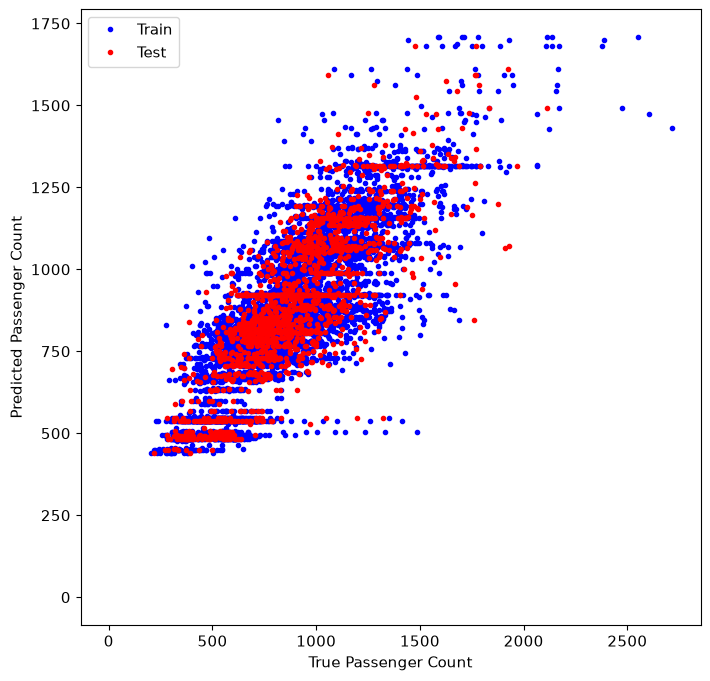

In [22]:
# Evaluate MSE, MAD, and R2 on train and test datasets

# Prediction:
y_p_train = reg.predict(x_train)
y_p_test = reg.predict(x_test)

# mse
print('Train MSE = %5.2f' % np.std(y_train - y_p_train))
print('Test MSE = %5.2f' % np.std(y_test - y_p_test))
# mae
print('Train MAE = %5.2f' % np.mean(np.abs(y_train - y_p_train)))
print('Test MAE = %5.2f' % np.mean(np.abs(y_test - y_p_test)))
# R2
print('Train R2 = %5.2f' % reg.score(x_train, y_train))
print('Test R2 = %5.2f' % reg.score(x_test, y_test))

# Plot y vs predicted y for test and train parts
plt.figure(figsize=(8,8))
plt.plot(y_train, y_p_train, 'b.', label='Train')
plt.plot(y_test, y_p_test, 'r.', label='Test')

plt.plot([0], [0], 'w.')  # dummy to have origin
plt.xlabel('True Passenger Count')
plt.ylabel('Predicted Passenger Count')
# plt.gca().set_aspect('equal')
plt.legend()
plt.plot()

### Results of the random forest

- A random forest regressor was successfully applied on the passenger data of two touristic lines enriched with weather and holiday data.
- It was hard to define a suitable max. depth. Either the model was overfitted, or the regression showed unresolved horizontal clusters.
- With average depth of the model, the mean error is in the range of 10-20%.
- Maybe some further feature engineering is needed to imporve the quality of the data set for such a regression.

### 4.2 Neuronal Network

The same data set with the features as defined above is now used to perform a prediction using a neuronal network.

We set aside **20% for final testing**, then use 25% of the remaining data for validation. This gives a 60/20/20 split.

We fit the input scaler on the **training set only**. We also scale the target values to help optimization, then convert predictions back to passengers for all the error plots.

In [12]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11})

In [13]:
df_X = passenger_frequencies_merged[feature_fields].copy()
df_X.replace(cleanup_nums, inplace=True)  # convert categorical variables to numerical
df_X = df_X.astype(float)
df_Y = passenger_frequencies_merged[target_field].copy()
df_Y = df_Y.to_numpy(dtype=float)

Xh_dev, Xh_test_raw, yh_dev, yh_test = train_test_split(
    df_X, df_Y, test_size=0.2, random_state=RANDOM_STATE,
)
Xh_train_raw, Xh_val_raw, yh_train, yh_val = train_test_split(
    Xh_dev, yh_dev, test_size=0.25, random_state=RANDOM_STATE,
)

feature_scaler = StandardScaler().fit(Xh_train_raw)
Xh_train = feature_scaler.transform(Xh_train_raw)
Xh_val = feature_scaler.transform(Xh_val_raw)

passenger_scaler = StandardScaler().fit(yh_train.reshape(-1, 1))
yh_train_scaled = passenger_scaler.transform(yh_train.reshape(-1, 1)).ravel()

def passengers_reconstructed(predictions):
    return passenger_scaler.inverse_transform(np.asarray(predictions).reshape(-1, 1)).ravel()

print(f'Train: {len(yh_train)}, validation: {len(yh_val)}, test: {len(yh_test)}')

Train: 4610, validation: 1537, test: 1537


### The training loop

For every batch, we **make predictions**, calculate the loss, calculate gradients with **backpropagation**, and let the optimizer **update the weights and biases**.

`optimizer.zero_grad()` clears gradients from the previous batch because PyTorch otherwise accumulates them. `loss.backward()` computes new gradients, and `optimizer.step()` updates the parameters.

The short function below performs **one epoch**.

For evaluation `model.eval()` and `torch.no_grad()` is used: we evaluate the current model without building a gradient computation graph. These calls do not train the model.

In [14]:
def train_one_epoch(model, loader, loss_function, optimizer):
    model.train()
    for inputs, targets in loader:
        optimizer.zero_grad()                 # Clear previous gradients
        predictions = model(inputs)           # Forward pass
        loss = loss_function(predictions, targets)
        loss.backward()                       # Backpropagation
        optimizer.step()                      # Update weights and biases

In [ ]:
torch.manual_seed(RANDOM_STATE)
passenger_model = nn.Sequential(
    nn.Linear(Xh_train.shape[1], 128), nn.ReLU(),
    # nn.Linear(128, 256), nn.ReLU(),
    # nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
passenger_loss = nn.MSELoss()
passenger_optimizer = torch.optim.Adam(passenger_model.parameters(), lr=0.005)
Xh_train_tensor = torch.tensor(Xh_train, dtype=torch.float32)
Xh_val_tensor = torch.tensor(Xh_val, dtype=torch.float32)
yh_train_tensor = torch.tensor(yh_train_scaled, dtype=torch.float32).reshape(-1, 1)
passenger_loader = DataLoader(
    TensorDataset(Xh_train_tensor, yh_train_tensor), batch_size=32, shuffle=True,
)
passenger_history = {'train_rmse': [], 'val_rmse': []}
passenger_predictions, passenger_saved_epochs = [], []
best_passenger_rmse = np.inf
n_epochs_passenger = 100

for epoch in range(1, n_epochs_passenger + 1):
    train_one_epoch(passenger_model, passenger_loader, passenger_loss, passenger_optimizer)
    passenger_model.eval()
    with torch.no_grad():
        train_prediction = passengers_reconstructed(passenger_model(Xh_train_tensor).numpy())
        val_prediction = passengers_reconstructed(passenger_model(Xh_val_tensor).numpy())
    train_rmse = np.sqrt(mean_squared_error(yh_train, train_prediction))
    val_rmse = np.sqrt(mean_squared_error(yh_val, val_prediction))
    passenger_history['train_rmse'].append(train_rmse)
    passenger_history['val_rmse'].append(val_rmse)
    if val_rmse < best_passenger_rmse:
        best_passenger_rmse = val_rmse
        best_passenger_epoch = epoch
        best_passenger_model = deepcopy(passenger_model)
    if epoch == 1 or epoch % 2 == 0:
        passenger_predictions.append(val_prediction.copy())
        passenger_saved_epochs.append(epoch)

print(passenger_model)
print('Trainable parameters:', sum(p.numel() for p in passenger_model.parameters()))
print(f'Best validation epoch: {best_passenger_epoch}; RMSE: {best_passenger_rmse:,.0f} PAX')

Sequential(
  (0): Linear(in_features=8, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Trainable parameters: 5313
Best validation epoch: 95; RMSE: 158 PAX


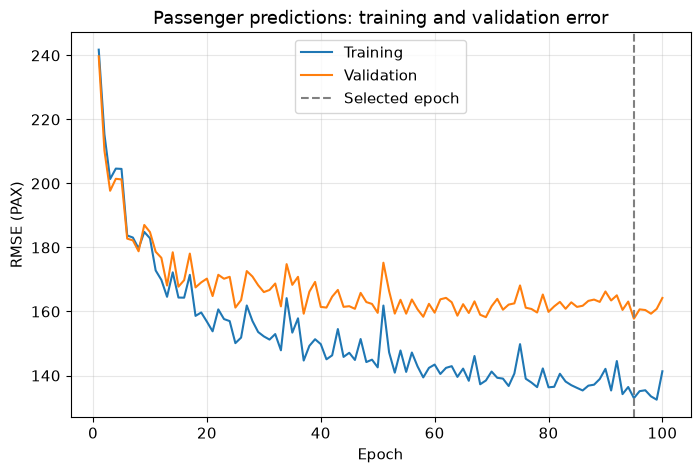

In [23]:
epochs_passenger = np.arange(1, n_epochs_passenger + 1)
fig, ax = plt.subplots()
ax.plot(epochs_passenger, passenger_history['train_rmse'], label='Training')
ax.plot(epochs_passenger, passenger_history['val_rmse'], label='Validation')
ax.axvline(best_passenger_epoch, color='grey', linestyle='--', label='Selected epoch')
ax.set(xlabel='Epoch', ylabel='RMSE (PAX)', title='Passenger predictions: training and validation error')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Watch the passenger number predictions improve

Each point is a validation trip. A perfect prediction would lie on the dashed diagonal. The epoch label matches the predictions saved during training.

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
passenger_line, = ax.plot(yh_val, passenger_predictions[0], 'o', alpha=0.4, markersize=4)
passenger_limits = [min(0, np.min(passenger_predictions), yh_val.min()),
                    max(np.max(passenger_predictions), yh_val.max()) * 1.05]
ax.plot(passenger_limits, passenger_limits, 'r--', label='Perfect prediction')
ax.set(xlabel='True passengers (#PAX)', ylabel='Predicted passengers (# PAX)',
       xlim=passenger_limits, ylim=passenger_limits)
ax.legend()
passenger_title = ax.set_title('')

def animate_passenger(frame):
    passenger_line.set_ydata(passenger_predictions[frame])
    passenger_title.set_text(f'Validation predictions: epoch {passenger_saved_epochs[frame]}')
    return passenger_line, passenger_title

passenger_animation = animation.FuncAnimation(
    fig, animate_passenger, frames=len(passenger_predictions), interval=150,
)
plt.close(fig)
display(HTML(passenger_animation.to_jshtml()))

After choosing the epoch using validation data, the model is evaluated once on the held-out test set.

In [44]:
Xh_test = feature_scaler.transform(Xh_test_raw)
best_passenger_model.eval()
with torch.no_grad():
    passenger_test_prediction = passengers_reconstructed(
        best_passenger_model(torch.tensor(Xh_test, dtype=torch.float32)).numpy()
    )
print(f'Test MAE: {mean_absolute_error(yh_test, passenger_test_prediction):,.0f} PAX')
print(f'Test RMSE: {np.sqrt(mean_squared_error(yh_test, passenger_test_prediction)):,.0f} PAX')

Test MAE: 113 PAX
Test RMSE: 152 PAX


### Results of the neuronal network

- A neuronal network was successfully applied on the passenger data of two touristic lines enriched with weather and holiday data.
- Increasing the number of hidden layers and neurons resulted in higher deviation of training and validation (overfitting).
- With a reasonable sized model, the mean error is very similar to the random forest.

## 5. Conclusion

- As in the clustering part, most of the time and effort goes into data preparation and feature engineering.
- The random forest, as well as the neuronal network were successfully applied to the combined passenger data set.
- The resulting errors are still to large for reasonable passenger predictions. Further work on the data set is needed to improve the model outcome.